In [1]:
import sys

import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__)

3.13.7 2.5.3 3.0.6 1.9.1


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 3042

data = pd.read_csv("data/heart_disease.csv")
feature_names = [c for c in data.columns if c != "disease"]
X, y = data[feature_names].to_numpy(), data["disease"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEED
)
print(data.shape, round(y.mean(), 3), X_train.shape, X_test.shape)

(297, 14) 0.461 (207, 13) (90, 13)


# Part 1: Entropy and information gain by hand

In [3]:
toy = pd.DataFrame({
    "age_55_plus": [1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0],
    "exercise_angina": [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0],
    "male": [1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0],
    "high_bp": [1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0],
    "disease": [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0],
})

def H(y):
    p = np.bincount(y) / len(y)
    p = p[p > 0]
    return -(p * np.log2(p)).sum()

def gain(d, f):
    y, m = d["disease"].to_numpy(), d[f].to_numpy() == 1
    return H(y) - (m.sum() * H(y[m]) + (~m).sum() * H(y[~m])) / len(y)

print("parent entropy:", H(toy["disease"].to_numpy()))
for f in ["age_55_plus", "exercise_angina", "male", "high_bp"]:
    print(f, round(gain(toy, f), 4))

branch = toy[toy["exercise_angina"] == 0]
for f in ["age_55_plus", "male", "high_bp"]:
    print("in branch:", f, round(gain(branch, f), 4))

parent entropy: 1.0
age_55_plus 0.35
exercise_angina 0.4591
male 0.0
high_bp 0.0817
in branch: age_55_plus 0.0738
in branch: male 0.2044
in branch: high_bp 0.0157


### 1. Parent entropy

The table has 12 patients: 6 with disease and 6 without.

H(parent) = −(6/12)·log₂(6/12) − (6/12)·log₂(6/12) = 0.5 + 0.5 = **1.0**

### 2. Information gain of each feature at the root

IG = H(parent) − weighted entropy of the two children.

| Feature | Child with value 1 | Child with value 0 | Weighted entropy | Gain |
|---|---|---|---|---|
| age_55_plus | 6 rows (5 sick, 1 healthy): H = −(5/6)·log₂(5/6) − (1/6)·log₂(1/6) = 0.219 + 0.431 = 0.650 | 6 rows (1 sick, 5 healthy): H = 0.650 | 6/12·0.650 + 6/12·0.650 = 0.650 | 1 − 0.650 = **0.350** |
| exercise_angina | 4 rows (all sick): H = 0 | 8 rows (2 sick, 6 healthy): H = −(2/8)·log₂(2/8) − (6/8)·log₂(6/8) = 0.5 + 0.311 = 0.811 | 4/12·0 + 8/12·0.811 = 0.541 | 1 − 0.541 = **0.459** |
| male | 6 rows (3 sick, 3 healthy): H = 1 | 6 rows (3 sick, 3 healthy): H = 1 | 1.0 | 1 − 1 = **0.000** |
| high_bp | 6 rows (4 sick, 2 healthy): H = −(4/6)·log₂(4/6) − (2/6)·log₂(2/6) = 0.390 + 0.528 = 0.918 | 6 rows (2 sick, 4 healthy): H = 0.918 | 0.918 | 1 − 0.918 = **0.082** |

The largest gain is for **exercise_angina (0.459)**, so it is the root of the tree.

### 3. One level down

The branch exercise_angina = 1 is pure (all 4 patients are sick), so it becomes a leaf.
The impure branch is **exercise_angina = 0**: 8 patients (2 sick, 6 healthy), H = 0.811.

| Feature | Child with value 1 | Child with value 0 | Weighted entropy | Gain |
|---|---|---|---|---|
| age_55_plus | 2 rows (1 sick, 1 healthy): H = 1 | 6 rows (1 sick, 5 healthy): H = 0.650 | 2/8·1 + 6/8·0.650 = 0.738 | 0.811 − 0.738 = **0.074** |
| male | 3 rows (all healthy): H = 0 | 5 rows (2 sick, 3 healthy): H = −(2/5)·log₂(2/5) − (3/5)·log₂(3/5) = 0.529 + 0.442 = 0.971 | 3/8·0 + 5/8·0.971 = 0.607 | 0.811 − 0.607 = **0.204** |
| high_bp | 3 rows (1 sick, 2 healthy): H = 0.918 | 5 rows (1 sick, 4 healthy): H = 0.722 | 3/8·0.918 + 5/8·0.722 = 0.796 | 0.811 − 0.796 = **0.016** |

The chosen feature is **male** (gain 0.204).

### 4. Why can a useless feature win below the root?

At the root, `male` has gain 0.000: among men and among women the split is exactly 3 sick / 3 healthy, so it tells us nothing on its own. But the root split on exercise_angina removes the four patients who all have the disease (three of them male). In the remaining branch every man is healthy, so `male` now separates the classes well (gain 0.204). A feature can be useless alone and useful once another feature has been used, because its effect depends on the other feature (an interaction).

# Part 2: Decision tree from scratch

In [4]:
def entropy(y):
    """Entropy in bits of an array of integer class labels."""
    y = np.asarray(y)
    if len(y) == 0:
        return 0.0
    p = np.bincount(y) / len(y)
    p = p[p > 0]  # drop zero probabilities so log2(0) never happens
    return float(-(p * np.log2(p)).sum())


def information_gain(y, left):
    """Entropy of y minus the size-weighted entropy of y[left] and y[~left]; left is a boolean mask."""
    y = np.asarray(y)
    left = np.asarray(left, dtype=bool)
    weighted = (left.sum() * entropy(y[left]) + (~left).sum() * entropy(y[~left])) / len(y)
    return entropy(y) - weighted

In [5]:
y_toy = toy["disease"].to_numpy()
print("parent entropy:", entropy(y_toy))
for f in ["age_55_plus", "exercise_angina", "male", "high_bp"]:
    print(f, round(information_gain(y_toy, toy[f].to_numpy() == 1), 4))

branch = toy[toy["exercise_angina"] == 0]
y_branch = branch["disease"].to_numpy()
for f in ["age_55_plus", "male", "high_bp"]:
    print("in branch:", f, round(information_gain(y_branch, branch[f].to_numpy() == 1), 4))

parent entropy: 1.0
age_55_plus 0.35
exercise_angina 0.4591
male 0.0
high_bp 0.0817
in branch: age_55_plus 0.0738
in branch: male 0.2044
in branch: high_bp 0.0157


## 2b. best_split
For every feature the candidate thresholds are the midpoints between consecutive distinct sorted values; rows with `x <= threshold` go left. A split is valid only if both children have at least `min_samples_leaf` rows. The split with the highest information gain is returned. Ties go to the lower feature index and then to the lower threshold: this holds because features and thresholds are scanned in increasing order and the best split is replaced only when a strictly larger gain is found (with a tiny tolerance against floating-point noise).

In [6]:
def best_split(X, y, min_samples_leaf=1):
    """Return (feature_index, threshold, gain) of the best split, or None if no valid split exists."""
    X = np.asarray(X)
    y = np.asarray(y)
    best = None
    for j in range(X.shape[1]):
        values = np.unique(X[:, j]) 
        thresholds = (values[:-1] + values[1:]) / 2  
        for t in thresholds:
            left = X[:, j] <= t
            n_left = int(left.sum())
            n_right = len(y) - n_left
            if n_left < min_samples_leaf or n_right < min_samples_leaf:
                continue 
            g = float(information_gain(y, left))
            if best is None or g > best[2] + 1e-12:
                best = (j, float(t), g)
    return best

In [7]:
toy_features = ["age_55_plus", "exercise_angina", "male", "high_bp"]
j, t, g = best_split(toy[toy_features].to_numpy(), y_toy)
print(toy_features[j], t, round(g, 4))

exercise_angina 0.5 0.4591


In [8]:
from sklearn.tree import DecisionTreeClassifier  

j, t, g = best_split(X_train, y_train)
print("mine:   ", feature_names[j], t, round(g, 4))

ref = DecisionTreeClassifier(criterion="entropy", max_depth=1, random_state=SEED).fit(X_train, y_train)
print("sklearn:", feature_names[ref.tree_.feature[0]], ref.tree_.threshold[0])

mine:    thal 4.5 0.2316
sklearn: thal 4.5


## 2c. build_tree and predict_tree

The tree is stored as nested dicts. An internal node holds the feature index, the threshold and its two children; a leaf holds the predicted class. A node becomes a leaf when it is pure, when `depth == max_depth`, or when `best_split` finds no valid split. A leaf predicts its majority class; a tie goes to the smaller label (`np.argmax` returns the first maximum).

In [9]:
def majority_class(y):
    """Most frequent label in y; a tie goes to the smaller label."""
    return int(np.argmax(np.bincount(y)))


def build_tree(X, y, max_depth=None, min_samples_leaf=1, depth=0):
    """Grow a tree recursively and return it as nested dicts (or any structure you like)."""
    X = np.asarray(X)
    y = np.asarray(y)
    prediction = majority_class(y)
    leaf = {"leaf": True, "prediction": prediction, "n": len(y)}

    if len(np.unique(y)) == 1:  
        return leaf
    if max_depth is not None and depth >= max_depth:  
        return leaf
    split = best_split(X, y, min_samples_leaf)
    if split is None:  
        return leaf

    j, t, g = split
    left = X[:, j] <= t
    return {
        "leaf": False,
        "feature": j,
        "threshold": t,
        "gain": g,
        "n": len(y),
        "prediction": prediction,
        "left": build_tree(X[left], y[left], max_depth, min_samples_leaf, depth + 1),
        "right": build_tree(X[~left], y[~left], max_depth, min_samples_leaf, depth + 1),
    }


def predict_tree(tree, X):
    """Return one predicted label per row of X."""
    X = np.asarray(X)
    predictions = []
    for row in X:
        node = tree
        while not node["leaf"]:
            node = node["left"] if row[node["feature"]] <= node["threshold"] else node["right"]
        predictions.append(node["prediction"])
    return np.array(predictions)

In [10]:
tree1 = build_tree(X_train, y_train, max_depth=1)
print("root:", feature_names[tree1["feature"]], tree1["threshold"], round(tree1["gain"], 4))
print("left leaf:", tree1["left"]["prediction"], "n =", tree1["left"]["n"])
print("right leaf:", tree1["right"]["prediction"], "n =", tree1["right"]["n"])
print("depth 1: train acc", round((predict_tree(tree1, X_train) == y_train).mean(), 4),
      "test acc", round((predict_tree(tree1, X_test) == y_test).mean(), 4))

root: thal 4.5 0.2316
left leaf: 0 n = 114
right leaf: 1 n = 93
depth 1: train acc 0.7778 test acc 0.7333


In [11]:
tree_full = build_tree(X_train, y_train)
print("unlimited depth: train acc", round((predict_tree(tree_full, X_train) == y_train).mean(), 4),
      "test acc", round((predict_tree(tree_full, X_test) == y_test).mean(), 4))

unlimited depth: train acc 1.0 test acc 0.7444


## 2d. Comparison with scikit-learn

For `max_depth` = 1, 2, 3, 4, 5 and unlimited I build my tree and scikit-learn's `DecisionTreeClassifier(criterion="entropy", random_state=SEED)` on the training split, and measure the fraction of test rows on which the two predict the same label.

In [12]:
depths = [1, 2, 3, 4, 5, None]
rows = []
for d in depths:
    mine = build_tree(X_train, y_train, max_depth=d)
    ref = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=SEED).fit(X_train, y_train)
    pred_mine = predict_tree(mine, X_test)
    pred_ref = ref.predict(X_test)
    rows.append({
        "max_depth": "unlimited" if d is None else d,
        "agreement": round((pred_mine == pred_ref).mean(), 4),
        "rows differing": int((pred_mine != pred_ref).sum()),
    })

agreement_table = pd.DataFrame(rows)
print(agreement_table.to_string(index=False))

max_depth  agreement  rows differing
        1     1.0000               0
        2     1.0000               0
        3     1.0000               0
        4     1.0000               0
        5     0.9333               6
unlimited     0.8889              10


In [13]:
# Does the agreement change when only scikit-learn's random_state changes?
for rs in [0, 1, 2, 3, SEED]:
    ref = DecisionTreeClassifier(criterion="entropy", random_state=rs).fit(X_train, y_train)
    print("random_state =", rs, "agreement:", round((predict_tree(tree_full, X_test) == ref.predict(X_test)).mean(), 4))

random_state = 0 agreement: 0.9444
random_state = 1 agreement: 0.9333
random_state = 2 agreement: 0.9556
random_state = 3 agreement: 0.9
random_state = 3042 agreement: 0.8889


### Part 2 results

| Question | Answer |
|---|---|
| 1. Do `entropy` and `information_gain` reproduce the Part 1 values? | Yes: parent entropy 1.0; root gains 0.35 / 0.4591 / 0.0 / 0.0817; gains in the impure branch 0.0738 / 0.2044 / 0.0157. |
| 2. Does `best_split` choose the same feature and threshold as scikit-learn? | Yes: both choose `thal` with threshold 4.5 (my information gain is 0.2316). |
| 3. Agreement with scikit-learn on the 90 test rows | depth 1 to 4: 100%; depth 5: 93.33% (6 rows differ); unlimited depth: 88.89% (10 rows differ). |

**Why is the agreement below 100% for depth 5 and unlimited depth?** The reason is ties. Deep in the tree the nodes contain only a few rows, and several (feature, threshold) pairs reach exactly the same information gain. My rule breaks such a tie by the lower feature index and then the lower threshold. scikit-learn goes through the features in a random order (controlled by `random_state`) and keeps the first best split it meets, so it can choose a different but equally good split. This is confirmed by the last experiment: when only scikit-learn's `random_state` changes, its agreement with my tree changes too (between 0.89 and 0.96), so the difference comes from tie-breaking and not from a bug.

# Part 3: How deep should the tree be?

Everything in this part uses only the training split (5-fold stratified cross-validation). The test split is not touched until step 3e.

## 3a. Depth sweep

In [14]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

In [15]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, None]
rows = []
for d in depths:
    model = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=SEED)
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy", return_train_score=True)
    n_leaves = model.fit(X_train, y_train).get_n_leaves() 
    rows.append({
        "max_depth": "None" if d is None else d,
        "leaves": int(n_leaves),
        "train_acc": round(scores["train_score"].mean(), 4),
        "cv_acc": round(scores["test_score"].mean(), 4),
        "cv_std": round(scores["test_score"].std(), 4),
    })

depth_table = pd.DataFrame(rows)
print(depth_table.to_string(index=False))

max_depth  leaves  train_acc  cv_acc  cv_std
        1       2     0.7778  0.7778  0.0556
        2       4     0.8067  0.7393  0.0709
        3       8     0.8381  0.7441  0.0310
        4      15     0.8816  0.7300  0.0485
        5      23     0.9251  0.7197  0.0549
        6      29     0.9528  0.7057  0.0641
        8      35     0.9855  0.7202  0.0680
       10      36     0.9964  0.6912  0.0516
     None      36     1.0000  0.7007  0.0406


## 3b. Plot: training and cross-validation accuracy against depth

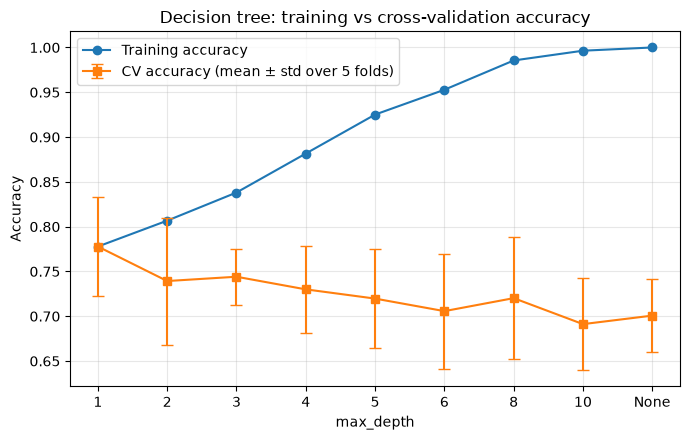

In [16]:
import matplotlib.pyplot as plt

x = np.arange(len(depth_table)) 
plt.figure(figsize=(7, 4.5))
plt.plot(x, depth_table["train_acc"], marker="o", label="Training accuracy")
plt.errorbar(
    x, depth_table["cv_acc"], yerr=depth_table["cv_std"],
    marker="s", capsize=4, label="CV accuracy (mean ± std over 5 folds)",
)
plt.xticks(x, depth_table["max_depth"].astype(str))
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision tree: training vs cross-validation accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("depth_sweep.png", dpi=150)
plt.show()

## 3c. Choosing a depth

### Selection rule

The highest mean alone is not a good criterion, because the CV accuracy of every depth is an average over only 5 folds and the folds differ from each other by several percentage points. I use the **one-standard-error rule**:

1. find the depth with the highest mean CV accuracy and compute its standard error SE = std / √5;
2. keep every depth whose mean CV accuracy is at least (best mean − SE);
3. among the kept depths choose the smallest one, i.e. the simplest tree.

A depth is called *clearly better* than a neighbour only if the difference of their mean CV accuracies is larger than the larger of the two fold standard deviations.

In [17]:
n_folds = cv.get_n_splits()
best = depth_table.loc[depth_table["cv_acc"].idxmax()]
se = best["cv_std"] / np.sqrt(n_folds)
threshold = best["cv_acc"] - se
candidates = depth_table[depth_table["cv_acc"] >= threshold]  
chosen = candidates.iloc[0]
chosen_depth = int(chosen["max_depth"])

print("best mean:", best["max_depth"], best["cv_acc"], "std", best["cv_std"], "SE", round(se, 4))
print("threshold:", round(threshold, 4))
print("depths kept:", candidates["max_depth"].tolist())
print("chosen depth:", chosen_depth)

for d in [2, 3]:
    other = depth_table[depth_table["max_depth"] == d].iloc[0]
    diff = chosen["cv_acc"] - other["cv_acc"]
    spread = max(chosen["cv_std"], other["cv_std"])
    print(f"depth {chosen_depth} vs depth {d}: difference {diff:.4f}, larger fold std {spread:.4f}, clearly better: {diff > spread}")

best mean: 1 0.7778 std 0.0556 SE 0.0249
threshold: 0.7529
depths kept: [1]
chosen depth: 1
depth 1 vs depth 2: difference 0.0385, larger fold std 0.0709, clearly better: False
depth 1 vs depth 3: difference 0.0337, larger fold std 0.0556, clearly better: False


### Chosen depth

By this rule the chosen depth is **max_depth = 1**. It has the highest mean CV accuracy (0.7778) and is also the simplest tree (2 leaves), so no deeper tree comes within one standard error (0.0249) of it.

Is it clearly better than its neighbours? **No.** Its advantage over depth 2 (0.0385) and depth 3 (0.0337) is smaller than the fold-to-fold standard deviation (0.0709 and 0.0556 respectively), so with 5 folds depths 1 to 3 cannot be told apart from noise. I keep depth 1 because, when accuracies are indistinguishable, the simplest tree is the safest choice. What the data do show clearly is that going deeper does not help: from depth 6 on, the training accuracy climbs to 0.95 to 1.0 while the CV accuracy does not improve.

## 3d. A second brake: min_samples_leaf

Same procedure (same folds `cv`, training split only), but now the depth is unlimited and `min_samples_leaf` takes the values 1, 2, 5, 10, 20, 40.

In [18]:
leaf_sizes = [1, 2, 5, 10, 20, 40]
rows = []
for m in leaf_sizes:
    model = DecisionTreeClassifier(criterion="entropy", min_samples_leaf=m, random_state=SEED)
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy", return_train_score=True)
    n_leaves = model.fit(X_train, y_train).get_n_leaves()
    rows.append({
        "min_samples_leaf": m,
        "leaves": int(n_leaves),
        "train_acc": round(scores["train_score"].mean(), 4),
        "cv_acc": round(scores["test_score"].mean(), 4),
        "cv_std": round(scores["test_score"].std(), 4),
    })

leaf_table = pd.DataFrame(rows)
print(leaf_table.to_string(index=False))

 min_samples_leaf  leaves  train_acc  cv_acc  cv_std
                1      36     1.0000  0.7007  0.0406
                2      33     0.9638  0.7102  0.0545
                5      21     0.8974  0.7245  0.0260
               10      13     0.8478  0.8017  0.0330
               20       7     0.7971  0.7297  0.0473
               40       4     0.7778  0.7778  0.0556


### Comparison of the two brakes

`max_depth` cuts the tree at a fixed number of levels everywhere, whereas `min_samples_leaf` only forbids leaves with few patients, so the tree can still grow deep where there is plenty of data and stops where it would fit a handful of rows. Here `min_samples_leaf = 10` gave the highest mean CV accuracy of both sweeps (0.8017 with 13 leaves), but its lead over depth 1 (0.7778) is only 0.024, smaller than the fold standard deviations (0.033 and 0.056), so I cannot call it better than the shallow tree.

## 3e. Test once

The chosen model (`max_depth = 1`, chosen in 3c) is fitted on the full training split and evaluated on the test split a single time. The standard error of the accuracy is sqrt(p·(1−p)/n), where p is the test accuracy and n the number of test patients.

In [19]:
final_tree = DecisionTreeClassifier(criterion="entropy", max_depth=chosen_depth, random_state=SEED)
final_tree.fit(X_train, y_train)

test_acc = final_tree.score(X_test, y_test)
n_test = len(y_test)
se_test = np.sqrt(test_acc * (1 - test_acc) / n_test)

print(f"test accuracy: {test_acc:.4f} (n = {n_test}, correct = {int(round(test_acc * n_test))})")
print(f"standard error: {se_test:.4f}")
print(f"approx. interval: {test_acc - se_test:.4f} to {test_acc + se_test:.4f}")

test accuracy: 0.7333 (n = 90, correct = 66)
standard error: 0.0466
approx. interval: 0.6867 to 0.7799


### Part 3 summary

- Depth sweep table: step 3a. Plot of training and CV accuracy against depth: step 3b.
- Selection rule (one-standard-error rule) and chosen depth: step 3c, **max_depth = 1**. Justification: it has the highest mean CV accuracy and is the simplest tree, but it is not clearly better than depths 2 and 3, whose differences are within the fold spread.
- Comparison of the two brakes: step 3d.
- Test accuracy of the chosen model: **0.7333 ± 0.0466** (66 of 90 test patients; the second number is the standard error).

**What does the gap at `max_depth = None` tell us?** The training accuracy is 1.0000 but the CV accuracy is only 0.7007, so the unlimited tree memorises the training patients and about 30 percentage points of its training accuracy do not carry over to new patients: this gap is overfitting.

# Part 4: Tree or logistic regression?

## 4a. Cross-validation on the training split

Three models are compared on the same 5 folds `cv`: the tree chosen in Part 3 (`max_depth = 1`), an unlimited-depth tree, and logistic regression. The scaler of logistic regression sits inside a pipeline, so it is fitted on the training part of each fold only.

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "tree (max_depth=1)": DecisionTreeClassifier(criterion="entropy", max_depth=chosen_depth, random_state=SEED),
    "tree (unlimited depth)": DecisionTreeClassifier(criterion="entropy", max_depth=None, random_state=SEED),
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
}

rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=("accuracy", "f1"))
    rows.append({
        "model": name,
        "cv_acc_mean": round(scores["test_accuracy"].mean(), 4),
        "cv_acc_std": round(scores["test_accuracy"].std(), 4),
        "cv_f1_mean": round(scores["test_f1"].mean(), 4),
    })

cv_table = pd.DataFrame(rows)
print(cv_table.to_string(index=False))

                 model  cv_acc_mean  cv_acc_std  cv_f1_mean
    tree (max_depth=1)       0.7778      0.0556      0.7546
tree (unlimited depth)       0.7007      0.0406      0.6670
   logistic regression       0.8357      0.0327      0.8175


## 4b. Does a tree need scaling?

The chosen tree is fitted on `X_train` and again on `StandardScaler().fit(X_train).transform(X_train)`. The test rows are transformed with the same scaler for the second tree. I report the fraction of test rows with the same prediction.

In [21]:
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

tree_raw = DecisionTreeClassifier(criterion="entropy", max_depth=chosen_depth, random_state=SEED).fit(X_train, y_train)
tree_scaled = DecisionTreeClassifier(criterion="entropy", max_depth=chosen_depth, random_state=SEED).fit(X_train_scaled, y_train)

same = (tree_raw.predict(X_test) == tree_scaled.predict(X_test_scaled)).mean()
j = tree_raw.tree_.feature[0]
print("fraction of test rows with the same prediction:", round(same, 4))
print("raw root:", feature_names[j], tree_raw.tree_.threshold[0])
print("scaled root:", feature_names[tree_scaled.tree_.feature[0]], round(tree_scaled.tree_.threshold[0], 4))
print("raw threshold on the scaled axis:", round((tree_raw.tree_.threshold[0] - scaler.mean_[j]) / scaler.scale_[j], 4))

fraction of test rows with the same prediction: 1.0
raw root: thal 4.5
scaled root: thal -0.1234
raw threshold on the scaled axis: -0.1234


### Why the predictions are identical

A tree only asks questions of the form "is feature j ≤ t?". Standardisation computes x' = (x − mean) / scale with scale > 0, which is a strictly increasing function, so it keeps the order of the values of every feature. The same rows therefore go left and right at every split, every split has the same information gain, and only the threshold is written in other units (here 4.5 on the raw scale is −0.1234 on the standardised scale). This is why the two trees agree on 100% of the test rows. Logistic regression is different: its coefficients and its regularisation depend on the scale of each feature, so it needs the scaler (which is why it sits in a pipeline).

## 4c. Hold-out, once

The tree (`max_depth = 1`) and logistic regression are fitted on the full training split and evaluated on the test split. In each confusion matrix the rows are the true class (0 = no disease, 1 = disease) and the columns are the predicted class.

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(X_train, y_train)

holdout_models = {"tree (max_depth=1)": final_tree, "logistic regression": logreg}
for name, model in holdout_models.items():
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    se = np.sqrt(acc * (1 - acc) / len(y_test))
    print(f"{name}: accuracy {acc:.4f} (SE {se:.4f}), F1 {f1_score(y_test, pred):.4f}")
    print(confusion_matrix(y_test, pred))
    print()